# OpenVaccine training set

Each row of `train.json` is one short RNA. The experiment measured, at each of the first 68 nucleotides, how reactive that base is and how fast the backbone degrades under four conditions. The model has to predict those five numbers from the sequence and a predicted secondary structure.

Three of the five are scored in the competition: `reactivity`, `deg_Mg_pH10`, and `deg_Mg_50C`.

## Load

In [1]:
import os
import tempfile
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", tempfile.mkdtemp(prefix="mpl-"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

CANDIDATES = [
    Path("../data/stanford-covid-vaccine/train.json"),
    Path("data/stanford-covid-vaccine/train.json"),
]
train_path = next(path for path in CANDIDATES if path.exists())
train = pd.read_json(train_path, lines=True)

TARGETS = ["reactivity", "deg_Mg_pH10", "deg_pH10", "deg_Mg_50C", "deg_50C"]
SCORED = ["reactivity", "deg_Mg_pH10", "deg_Mg_50C"]
ERRORS = {
    "reactivity": "reactivity_error",
    "deg_Mg_pH10": "deg_error_Mg_pH10",
    "deg_pH10": "deg_error_pH10",
    "deg_Mg_50C": "deg_error_Mg_50C",
    "deg_50C": "deg_error_50C",
}
TARGET_LABELS = {
    "reactivity": "reactivity",
    "deg_Mg_pH10": "deg, Mg / pH 10",
    "deg_pH10": "deg, pH 10",
    "deg_Mg_50C": "deg, Mg / 50 C",
    "deg_50C": "deg, 50 C",
}
LOOP_ORDER = ["S", "H", "I", "B", "M", "X", "E"]
LOOP_NAMES = {
    "S": "stem",
    "H": "hairpin",
    "I": "internal loop",
    "B": "bulge",
    "M": "multiloop",
    "X": "external loop",
    "E": "dangling end",
}

train.shape

Matplotlib is building the font cache; this may take a moment.


(2400, 19)

## What is in a row

`sequence`, `structure`, and `predicted_loop_type` are strings of length `seq_length` (107). The five target columns, and their matching error columns, are lists of length `seq_scored` (68). Only that prefix was measured. `signal_to_noise` summarizes how large the measurements are relative to their errors. `SN_filter` is 1 when a molecule passed the host's quality cut.

In [2]:
train[["id", "sequence", "structure", "predicted_loop_type", "signal_to_noise", "SN_filter", "seq_length", "seq_scored"]].head(3)

,id,sequence,structure,predicted_loop_type,signal_to_noise,SN_filter,seq_length,seq_scored
0,id_001f94081,GGAAAAGCUCUAAUAACAGGAGACUAGGACUACGUAUUUCUAGGUA...,.....((((((.......)))).)).((.....((..((((((......,EEEEESSSSSSHHHHHHHSSSSBSSXSSIIIIISSIISSSSSSHHH...,6.894,1,107,68
1,id_0049f53ba,GGAAAAAGCGCGCGCGGUUAGCGCGCGCUUUUGCGCGCGCUGUACC...,.....(((((((((((((((((((((((....)))))))))).)))...,EEEEESSSSSSSSSSSSSSSSSSSSSSSHHHHSSSSSSSSSSBSSS...,0.193,0,107,68
2,id_006f36f57,GGAAAGUGCUCAGAUAAGCUAAGCUCGAAUAGCAAUCGAAUAGAAU...,.....((((.((.....((((.(((.....)))..((((......)...,EEEEESSSSISSIIIIISSSSMSSSHHHHHSSSMMSSSSHHHHHHS...,8.800,1,107,68


In [3]:
print(f"{len(train)} molecules")
print("seq_length:", sorted(train.seq_length.unique().tolist()))
print("seq_scored:", sorted(train.seq_scored.unique().tolist()))
print("target list lengths:", {col: train[col].map(len).unique().tolist() for col in TARGETS})
print("missing values in scalar columns:", int(train[["signal_to_noise", "SN_filter", "sequence", "structure"]].isna().sum().sum()))

2400 molecules
seq_length: [107]
seq_scored: [68]
target list lengths: {'reactivity': [68], 'deg_Mg_pH10': [68], 'deg_pH10': [68], 'deg_Mg_50C': [68], 'deg_50C': [68]}
missing values in scalar columns: 0


## Signal-to-noise filter

The hosts recommend training on `SN_filter == 1`. That flag requires signal-to-noise above 1 and a few other read-quality checks. Molecules that fail any check stay in the file, including some whose signal-to-noise is still above 1.

SN_filter = 1: 1589
SN_filter = 0: 811
            count   mean    std    min    25%    50%    75%     max
SN_filter                                                          
0           811.0  2.822  2.626 -0.103  0.582  2.259  4.592  15.866
1          1589.0  5.402  2.525  0.993  3.484  5.222  6.853  17.194


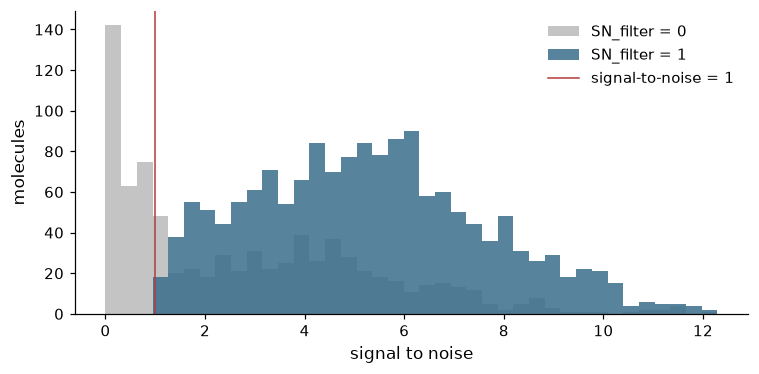

In [4]:
n_pass = int((train.SN_filter == 1).sum())
n_fail = int((train.SN_filter == 0).sum())
print(f"SN_filter = 1: {n_pass}")
print(f"SN_filter = 0: {n_fail}")
print(train.groupby("SN_filter")["signal_to_noise"].describe().round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0, train.signal_to_noise.quantile(0.99), 40)
ax.hist(train.loc[train.SN_filter == 0, "signal_to_noise"], bins=bins, label="SN_filter = 0", color="#c4c4c4")
ax.hist(train.loc[train.SN_filter == 1, "signal_to_noise"], bins=bins, label="SN_filter = 1", color="#3b6d8c", alpha=0.85)
ax.axvline(1, color="#b33b3b", lw=1, label="signal-to-noise = 1")
ax.set_xlabel("signal to noise")
ax.set_ylabel("molecules")
ax.legend(frameon=False)
fig.tight_layout()

## Sequence and predicted structure

Bases are A, C, G, and U. `structure` uses `(` and `)` for a predicted base pair and `.` for an unpaired base. `predicted_loop_type` is the bpRNA label of that predicted fold: stem, hairpin, internal loop, bulge, multiloop, external loop, or dangling end.

sequences where '(' count differs from ')': 0
unique 5' scored prefixes: 1 GGAAA
unique 3' tails of the full sequence: 1


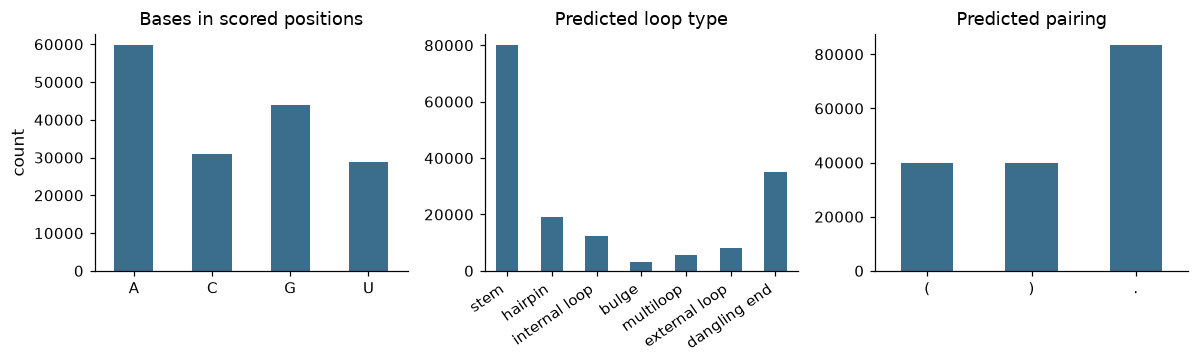

In [5]:
scored_n = int(train.seq_scored.iloc[0])
bases = np.array([list(seq[:scored_n]) for seq in train.sequence])
loops = np.array([list(loop[:scored_n]) for loop in train.predicted_loop_type])
struct = np.array([list(s[:scored_n]) for s in train.structure])

base_counts = pd.Series(bases.ravel()).value_counts().reindex(list("ACGU"))
loop_counts = pd.Series(loops.ravel()).value_counts().reindex(LOOP_ORDER)
struct_counts = pd.Series(struct.ravel()).value_counts().reindex(list("().") )

open_counts = train.structure.str.count(r"\(")
close_counts = train.structure.str.count(r"\)")
print("sequences where '(' count differs from ')':", int((open_counts != close_counts).sum()))
print("unique 5' scored prefixes:", train.sequence.str[:5].nunique(), train.sequence.str[:5].iloc[0])
print("unique 3' tails of the full sequence:", train.sequence.str[-21:].nunique())

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
base_counts.plot.bar(ax=axes[0], color="#3b6d8c", rot=0)
axes[0].set_title("Bases in scored positions")
axes[0].set_ylabel("count")
loop_counts.plot.bar(ax=axes[1], color="#3b6d8c", rot=0)
axes[1].set_title("Predicted loop type")
axes[1].set_xticklabels([LOOP_NAMES[k] for k in LOOP_ORDER], rotation=35, ha="right")
struct_counts.plot.bar(ax=axes[2], color="#3b6d8c", rot=0)
axes[2].set_title("Predicted pairing")
fig.tight_layout()

## Per-nucleotide measurements

The lists are expanded so each scored position is one row. The histograms below use every molecule. The later comparisons use only `SN_filter == 1`, because the dropped molecules are dominated by measurement noise.

163,200 scored positions from 2400 molecules


,target,mean,std,frac_negative,p50,p95
0,reactivity,0.379,0.456,0.030,0.217,1.289
1,deg_Mg_pH10,0.460,0.519,0.006,0.299,1.413
2,deg_pH10,0.448,0.567,0.017,0.278,1.449
3,deg_Mg_50C,0.412,0.491,0.018,0.260,1.330
4,deg_50C,0.426,0.425,0.020,0.314,1.209


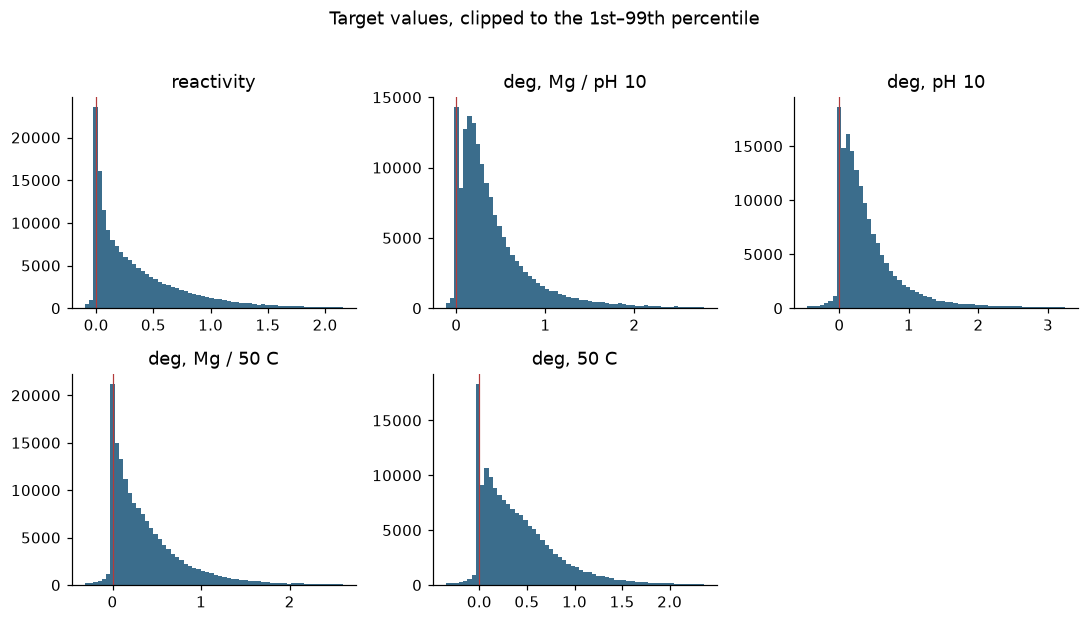

In [6]:
passed = train.SN_filter.to_numpy() == 1
nt_rows = len(train) * scored_n
print(f"{nt_rows:,} scored positions from {len(train)} molecules")

fig, axes = plt.subplots(2, 3, figsize=(10, 5.5))
axes = axes.ravel()
for ax, col in zip(axes, TARGETS):
    values = np.concatenate(train[col].to_numpy())
    lo, hi = np.quantile(values, [0.01, 0.99])
    ax.hist(values, bins=60, range=(lo, hi), color="#3b6d8c")
    ax.axvline(0, color="#b33b3b", lw=0.8)
    ax.set_title(TARGET_LABELS[col])
axes[-1].axis("off")
fig.suptitle("Target values, clipped to the 1st–99th percentile", y=1.02)
fig.tight_layout()

summary = []
for col in TARGETS:
    values = np.concatenate(train.loc[passed, col].to_numpy())
    summary.append({
        "target": col,
        "mean": values.mean(),
        "std": values.std(),
        "frac_negative": (values < 0).mean(),
        "p50": np.median(values),
        "p95": np.quantile(values, 0.95),
    })
pd.DataFrame(summary).round(3)

## Where along the chain the signal sits

Every training RNA shares the same length, and the constructs share fixed end regions. The mean at each scored position shows whether degradation is spread evenly or concentrated in the middle of the designed sequence.

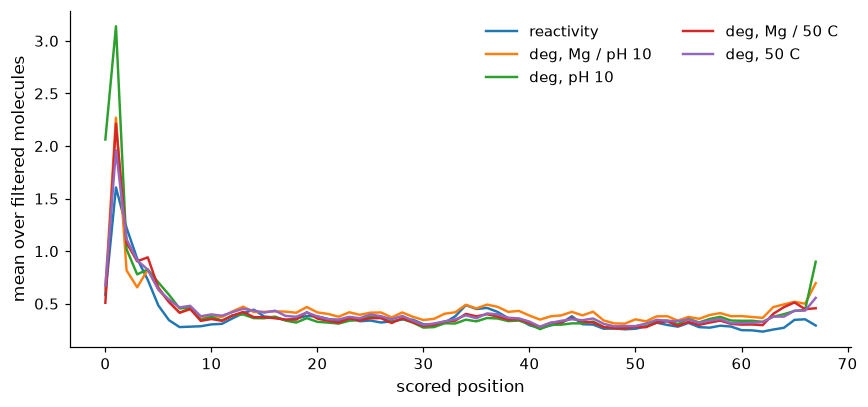

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
positions = np.arange(scored_n)
for col in TARGETS:
    matrix = np.stack(train.loc[passed, col].to_numpy())
    ax.plot(positions, matrix.mean(axis=0), label=TARGET_LABELS[col], lw=1.6)
ax.set_xlabel("scored position")
ax.set_ylabel("mean over filtered molecules")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()

## Base and loop type

Unpaired bases, especially in hairpins, are where degradation is expected to be higher. Stems should be quieter. These means are over filtered molecules only.

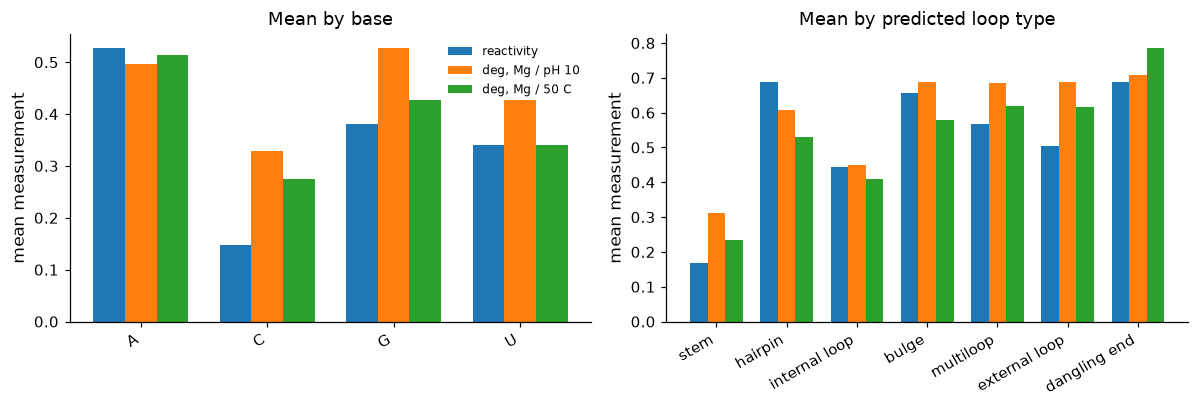

In [8]:
def mean_by(labels, label_order):
    rows = []
    for col in SCORED:
        matrix = np.stack(train.loc[passed, col].to_numpy())
        for label in label_order:
            mask = labels[passed] == label
            rows.append({"target": col, "group": label, "mean": matrix[mask].mean(), "n": int(mask.sum())})
    return pd.DataFrame(rows)

by_base = mean_by(bases, list("ACGU"))
by_loop = mean_by(loops, LOOP_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, table, order, title, ticklabels in [
    (axes[0], by_base, list("ACGU"), "Mean by base", list("ACGU")),
    (axes[1], by_loop, LOOP_ORDER, "Mean by predicted loop type", [LOOP_NAMES[k] for k in LOOP_ORDER]),
]:
    width = 0.25
    x = np.arange(len(order))
    for i, col in enumerate(SCORED):
        part = table[table.target == col].set_index("group").loc[order, "mean"]
        ax.bar(x + (i - 1) * width, part, width=width, label=TARGET_LABELS[col])
    ax.set_xticks(x)
    ax.set_xticklabels(ticklabels, rotation=30, ha="right")
    ax.set_title(title)
    ax.set_ylabel("mean measurement")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()

## Do the five measurements move together?

At a given position the five readouts are not independent. Magnesium conditions in particular tend to agree. Reactivity, which is a structure probe rather than a degradation rate, is the least aligned with the degradation columns.

,reactivity,deg_Mg_pH10,deg_pH10,deg_Mg_50C,deg_50C
reactivity,1.000,0.638,0.584,0.684,0.674
deg_Mg_pH10,0.638,1.000,0.748,0.872,0.733
deg_pH10,0.584,0.748,1.000,0.774,0.774
deg_Mg_50C,0.684,0.872,0.774,1.000,0.822
deg_50C,0.674,0.733,0.774,0.822,1.000


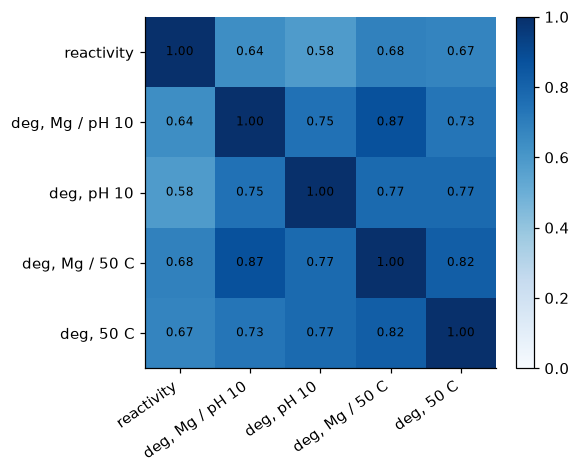

In [9]:
filtered_nt = {
    col: np.stack(train.loc[passed, col].to_numpy()).ravel()
    for col in TARGETS
}
corr = pd.DataFrame(filtered_nt).corr()

fig, ax = plt.subplots(figsize=(5.2, 4.4))
image = ax.imshow(corr, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(TARGETS)))
ax.set_yticks(range(len(TARGETS)))
ax.set_xticklabels([TARGET_LABELS[c] for c in TARGETS], rotation=35, ha="right")
ax.set_yticklabels([TARGET_LABELS[c] for c in TARGETS])
for i in range(len(TARGETS)):
    for j in range(len(TARGETS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
corr.round(3)

## Reported error

Each target value comes with an estimated error. The error grows with the size of the measurement, so a large degradation rate is also a less precise one. Positions with a huge error are exactly what `SN_filter` is meant to down-weight.

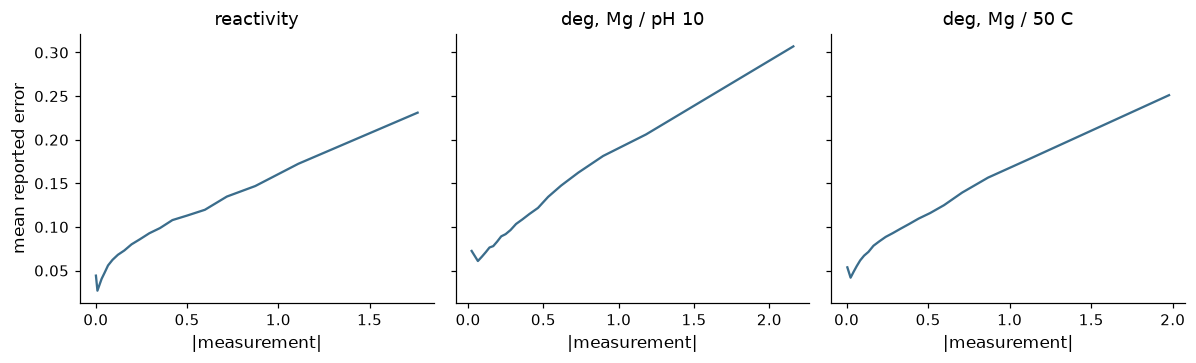

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, col in zip(axes, SCORED):
    value = np.stack(train.loc[passed, col].to_numpy()).ravel()
    error = np.stack(train.loc[passed, ERRORS[col]].to_numpy()).ravel()
    order = np.argsort(np.abs(value))
    bins = np.array_split(order, 20)
    centers = [np.abs(value[idx]).mean() for idx in bins]
    mean_error = [error[idx].mean() for idx in bins]
    ax.plot(centers, mean_error, color="#3b6d8c")
    ax.set_title(TARGET_LABELS[col])
    ax.set_xlabel("|measurement|")
axes[0].set_ylabel("mean reported error")
fig.tight_layout()

## One molecule

A single filtered example makes the per-base layout concrete. The x-axis is the scored prefix. Stems in the predicted structure are marked along the bottom.

id_e772efd1d signal_to_noise 12.4
GGAAAGGUGUAUUGUUUUGUAGGGAUCGACAAGGUUGUUAUAGAAUUGCCGGAGGGCAACCGGUGUUA
.....(((.....(((((((((.((((.....)))).)))))))))((((....))))))).......


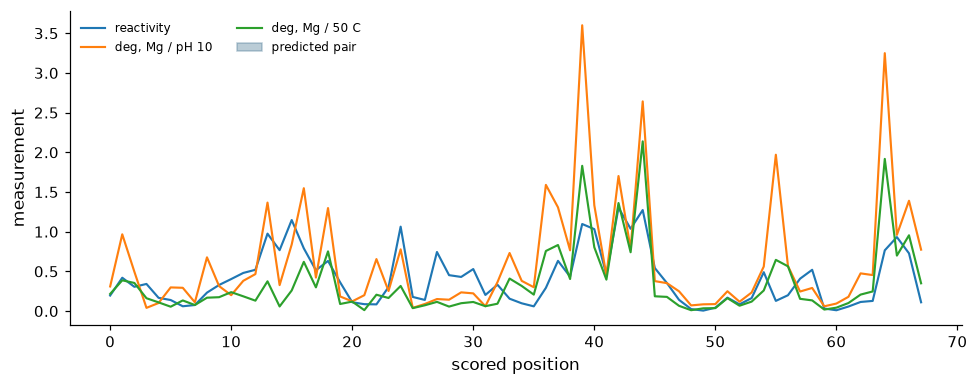

In [11]:
example = train.loc[passed].sort_values("signal_to_noise", ascending=False).iloc[20]
print(example.id, "signal_to_noise", round(float(example.signal_to_noise), 2))
print(example.sequence[:scored_n])
print(example.structure[:scored_n])

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(scored_n)
ax.plot(x, example.reactivity, label="reactivity", lw=1.4)
ax.plot(x, example.deg_Mg_pH10, label="deg, Mg / pH 10", lw=1.4)
ax.plot(x, example.deg_Mg_50C, label="deg, Mg / 50 C", lw=1.4)
paired = np.array([c != "." for c in example.structure[:scored_n]])
ax.fill_between(x, -0.15, -0.02, where=paired, color="#3b6d8c", alpha=0.35, transform=ax.get_xaxis_transform(), label="predicted pair")
ax.set_xlabel("scored position")
ax.set_ylabel("measurement")
ax.legend(frameon=False, ncol=2, fontsize=8)
fig.tight_layout()

## What this implies for a model

The training distribution is narrow in length: every RNA is 107 nucleotides, and the loss only sees the first 68. The private test is longer, so a model that memorizes position 0–67 rather than local sequence and structure will not transfer.

Most of the useful signal is in the 1,589 molecules with `SN_filter == 1`. The five targets are positively correlated, and the two magnesium degradation measurements are the closest pair. Hairpins and other unpaired contexts run hotter than stems. Reported errors scale with the measurement, so a plain squared error treats the noisiest positions as the most important.